## AC - Project - Exploratory Analysis

In this section we're going to analyse the following aspects:
- Class Balance
- Data Quality
- Feature Distributions
- Correlations
- Clinical Sense Check

**1. Setup and Imports**

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

out_dir = os.path.join('outputs', 'exploratory_analysis')
fig_dir = 'figures'  # figures used by main.tex
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

order = ['Low', 'Moderate', 'High']
colors = {'Low': '#4c9f70', 'Moderate': '#e0a030', 'High': '#c0392b'}

def save_fig(name):
    # saves the current figure in outputs/ and in figures/ (for the report)
    plt.savefig(os.path.join(out_dir, name), bbox_inches='tight')
    plt.savefig(os.path.join(fig_dir, name), bbox_inches='tight')

data = pd.read_csv('diabetes_risk.csv')
print(data.head(10))

   patient_id  age  gender       city   bmi family_history_diabetes  \
0           1   47  Female     Mumbai  26.5                     Yes   
1           2   53  Female     Mumbai  20.5                     Yes   
2           3   47    Male      Thane  31.3                      No   
3           4   41    Male  Bengaluru  22.8                      No   
4           5   57  Female  Bengaluru  16.7                      No   
5           6   58    Male  Hyderabad  22.0                      No   
6           7   42  Female  Hyderabad  22.5                      No   
7           8   42  Female      Delhi  19.5                      No   
8           9   57    Male     Mumbai  20.3                     Yes   
9          10   44    Male     Mumbai  24.1                      No   

  physical_activity_level       diet_type smoking_status alcohol_consumption  \
0               Sedentary      Vegetarian          Never               Never   
1                Moderate      Vegetarian          Never  

**2. Class Balance**

In [6]:
print ("Percentage of patients in each risk category:")

high_risk = (len(data[data['diabetes_risk'] == 'High']))/len(data) * 100
print ("High Risk: " + str(high_risk) + "%")

moderate_risk = (len(data[data['diabetes_risk'] == 'Moderate']))/len(data) * 100
print ("Moderate Risk: " + str(moderate_risk) + "%")

low_risk = (len(data[data['diabetes_risk'] == 'Low']))/len(data) * 100
print ("Low Risk: " + str(low_risk) + "%")

Percentage of patients in each risk category:
High Risk: 15.0%
Moderate Risk: 25.0%
Low Risk: 60.0%


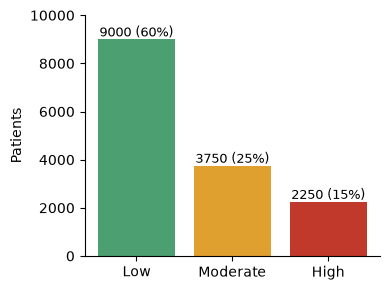

In [7]:
fig, ax = plt.subplots(figsize=(4, 3))
counts = data['diabetes_risk'].value_counts().reindex(order)
bars = ax.bar(order, counts.values, color=[colors[c] for c in order])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 120, f'{v} ({v / len(data):.0%})', ha='center', fontsize=9)
ax.set_ylabel('Patients')
ax.set_ylim(0, 10000)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
save_fig('eda_class_balance.pdf')
plt.show()

**3. Data Quality**
In this part, we'll make a table that for each feature, we:
- count missing values;
- count duplicate rows;
- check for outliers.

In [8]:
rows = []
for col in data.columns:
    feature = data[col]
    is_numeric = pd.api.types.is_numeric_dtype(feature)
    rows.append({
        'feature': col,
        'type': 'numeric' if is_numeric else 'categorical',
        'missing_values': feature.isnull().sum(),
        'min': feature.min() if is_numeric else None,
        'max': feature.max() if is_numeric else None,
        'levels': '-' if is_numeric else ', '.join(map(str, feature.dropna().unique())),
    })  

data_quality = pd.DataFrame(rows)
print(data_quality)
data_quality.to_csv(os.path.join(out_dir, 'data_quality.csv'), index=False)
print('Duplicate rows:', data.duplicated().sum())


                     feature         type  missing_values   min      max  \
0                 patient_id      numeric               0   1.0  15000.0   
1                        age      numeric               0  18.0     80.0   
2                     gender  categorical               0   NaN      NaN   
3                       city  categorical               0   NaN      NaN   
4                        bmi      numeric               0  15.0     40.8   
5    family_history_diabetes  categorical               0   NaN      NaN   
6    physical_activity_level  categorical               0   NaN      NaN   
7                  diet_type  categorical               0   NaN      NaN   
8             smoking_status  categorical             472   NaN      NaN   
9        alcohol_consumption  categorical            3788   NaN      NaN   
10     hours_sleep_per_night      numeric               0   3.0     12.0   
11              stress_level      numeric               0   1.0     10.0   
12       fas

**Data quality - tables for the report**

Numeric and categorical features are summarised separately (`patient_id` is only an identifier, so it is left out).

In [9]:
features = data.drop(columns=['patient_id'])

# Numeric features
num = features.select_dtypes('number')
numeric_table = pd.DataFrame({
    'Missing': num.isna().sum(),
    'Min': num.min(),
    'Max': num.max(),
    'Mean': num.mean().round(2),
    'Std': num.std().round(2),
})
print(numeric_table)

# Categorical features (the target is not included)
cat = features.drop(columns=['diabetes_risk']).select_dtypes(exclude='number')
categorical_table = pd.DataFrame({
    'Missing': cat.isna().sum(),
    'Missing (%)': (cat.isna().mean() * 100).round(1),
    'Levels': cat.nunique(),
})
print(categorical_table)

numeric_table.to_csv(os.path.join(out_dir, 'numeric_table.csv'))
categorical_table.to_csv(os.path.join(out_dir, 'categorical_table.csv'))

print('Rows with at least one missing value:', features.isna().any(axis=1).sum())

                          Missing   Min    Max    Mean    Std
age                             0  18.0   80.0   44.33  10.38
bmi                             0  15.0   40.8   23.06   4.05
hours_sleep_per_night           0   3.0   12.0    7.31   1.11
stress_level                    0   1.0   10.0    5.94   2.15
fasting_blood_sugar             0  72.0  400.0  168.79  38.37
hba1c_level                     0   4.8   13.4    6.88   0.84
blood_pressure_systolic         0  80.0  200.0  139.50  12.66
blood_pressure_diastolic        0  50.0  120.0   86.26   8.39
waist_circumference_cm          0  73.2  148.2  100.21  10.76
                         Missing  Missing (%)  Levels
gender                         0          0.0       3
city                           0          0.0      18
family_history_diabetes        0          0.0       2
physical_activity_level        0          0.0       3
diet_type                      0          0.0       4
smoking_status               472          3.1       3
al

**Data quality - outliers and impossible values**

Outliers are detected with the IQR rule (values more than 1.5 x IQR outside the quartiles) and the class distribution of the flagged patients is shown. We also check that the diastolic pressure is below the systolic one.

In [10]:
rows = []
for col in num.columns:
    q1, q3 = num[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    is_outlier = (num[col] < q1 - 1.5 * iqr) | (num[col] > q3 + 1.5 * iqr)
    share = data.loc[is_outlier, 'diabetes_risk'].value_counts(normalize=True).reindex(order).fillna(0).round(2)
    rows.append({
        'feature': col,
        'outliers': is_outlier.sum(),
        'outliers (%)': round(is_outlier.mean() * 100, 1),
        'Low': share['Low'], 'Moderate': share['Moderate'], 'High': share['High'],
    })

outliers = pd.DataFrame(rows).set_index('feature')
print(outliers)
outliers.to_csv(os.path.join(out_dir, 'outliers.csv'))

print('Diastolic >= systolic pressure:', (data['blood_pressure_diastolic'] >= data['blood_pressure_systolic']).sum())

                          outliers  outliers (%)   Low  Moderate  High
feature                                                               
age                              3           0.0  0.00      0.00  1.00
bmi                            153           1.0  0.12      0.39  0.50
hours_sleep_per_night          360           2.4  0.63      0.24  0.13
stress_level                     0           0.0  0.00      0.00  0.00
fasting_blood_sugar            432           2.9  0.01      0.00  0.98
hba1c_level                    355           2.4  0.00      0.01  0.99
blood_pressure_systolic         11           0.1  0.82      0.09  0.09
blood_pressure_diastolic       213           1.4  0.44      0.31  0.25
waist_circumference_cm         167           1.1  0.17      0.39  0.44
Diastolic >= systolic pressure: 2


**4. Feature Distributions**

Boxplots of each numeric feature by risk class, to see which features separate the classes, plus skewness and the target distribution for each categorical feature.

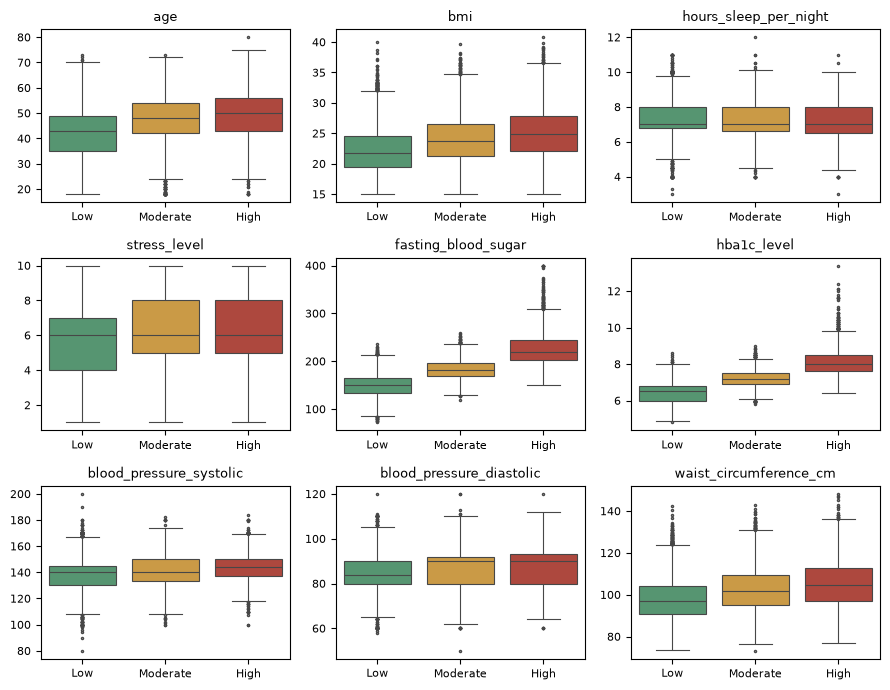

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(9, 7))
for ax, col in zip(axes.ravel(), num.columns):
    sns.boxplot(data=data, x='diabetes_risk', y=col, order=order, hue='diabetes_risk', hue_order=order,
                palette=colors, legend=False, ax=ax, fliersize=1.5, linewidth=0.8)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_title(col, fontsize=9)
    ax.tick_params(labelsize=8)
plt.tight_layout()
save_fig('eda_distributions.pdf')
plt.show()

**5. Correlations**

Pearson correlation between the numeric features. Pairs with a strong correlation are redundant and candidates for removal in feature selection.

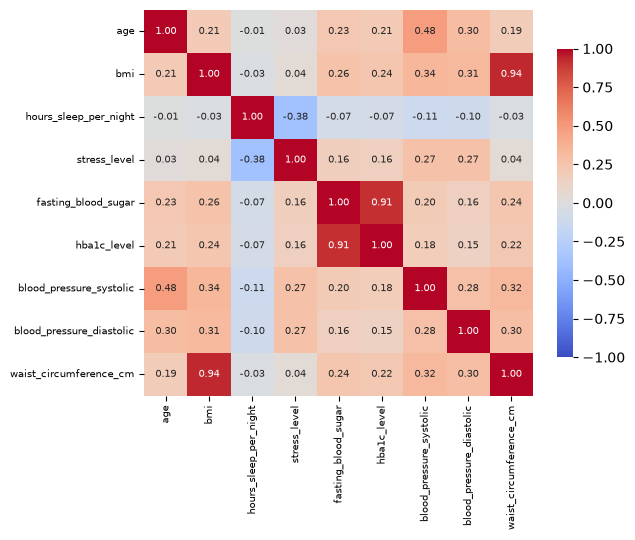

bmi                      waist_circumference_cm      0.94
fasting_blood_sugar      hba1c_level                 0.91
age                      blood_pressure_systolic     0.48
hours_sleep_per_night    stress_level               -0.38
bmi                      blood_pressure_systolic     0.34
blood_pressure_systolic  waist_circumference_cm      0.32
bmi                      blood_pressure_diastolic    0.31
age                      blood_pressure_diastolic    0.30
dtype: float64


In [14]:
corr = num.corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            annot_kws={'size': 7}, cbar_kws={'shrink': 0.8}, ax=ax)
ax.tick_params(labelsize=7)
plt.tight_layout()
save_fig('eda_correlations.pdf')
plt.show()

# Pairs with |r| > 0.3
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(pairs[pairs.abs() > 0.3].sort_values(key=abs, ascending=False).round(2))

**6. Clinical Sense Check**

Comparison with the clinical thresholds for diabetes: fasting glucose >= 126 mg/dL and HbA1c >= 6.5 %. The data are synthetic, so this shows how realistic they are.

In [15]:
high_glucose = data['fasting_blood_sugar'] >= 126
high_hba1c = data['hba1c_level'] >= 6.5

print('Patients above the glucose threshold: {:.1%}'.format(high_glucose.mean()))
print('Patients above the HbA1c threshold:   {:.1%}'.format(high_hba1c.mean()))
print()
print('Share above each threshold, per risk class:')
print(pd.DataFrame({
    'glucose >= 126': high_glucose.groupby(data['diabetes_risk']).mean(),
    'HbA1c >= 6.5': high_hba1c.groupby(data['diabetes_risk']).mean(),
}).reindex(order).round(2))

Patients above the glucose threshold: 87.3%
Patients above the HbA1c threshold:   69.0%

Share above each threshold, per risk class:
               glucose >= 126  HbA1c >= 6.5
diabetes_risk                              
Low                      0.79          0.50
Moderate                 1.00          0.95
High                     1.00          1.00
